In [5]:
import os
import cv2
import lmdb
import pickle
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from PIL import Image


# MultiGenSe

- read image names

In [2]:
fd = '/p/scratch/hai_ws4eo/liu_ch/data/WeakFT/test_data/multisenge'
fp_img = os.path.join(fd, 's2')
fp_label = os.path.join(fd, 'ground_reference')
fns_img = os.listdir(fp_img)    
fns_lbl = os.listdir(fp_label)
len(fns_img), len(fns_lbl)

(72033, 8157)

- pair label and image names

In [14]:
name_dict = {k:[] for k in fns_lbl}
dates = []
for fn in fns_img:
    fn_split = fn.split('_')
    fn_lbl = fn_split[0] + '_GR_' + fn_split[3] + '_' + fn_split[4]
    name_dict[fn_lbl].append(fn_split[1]) 
    dates.append(fn_split[1])
all_dates = np.unique(dates)
len(all_dates), all_dates

(52,
 array(['20200105', '20200106', '20200115', '20200116', '20200121',
        '20200207', '20200315', '20200318', '20200325', '20200402',
        '20200404', '20200407', '20200414', '20200417', '20200422',
        '20200507', '20200517', '20200519', '20200527', '20200529',
        '20200530', '20200601', '20200623', '20200624', '20200721',
        '20200723', '20200729', '20200731', '20200805', '20200807',
        '20200808', '20200812', '20200820', '20200904', '20200909',
        '20200911', '20200912', '20200914', '20200916', '20200917',
        '20200919', '20200921', '20200922', '20201031', '20201105',
        '20201106', '20201118', '20201121', '20201126', '20201128',
        '20201210', '20201218'], dtype='<U8'))

- check whether each label has at least one image paired

In [11]:
for k, v in name_dict.items():
    if len(v) == 0: print(k)

- randomly select images from jun-sep

In [15]:
selected_pair = {}
n_nod = 0
for k, v in name_dict.items():
    dlist = []
    for f in v:
        if f[:6] in ['202006', '202007', '202008', '202009']:
            dlist.append(f)
    if len(dlist) > 0:
        d = np.random.choice(dlist)
    else:
        d = np.random.choice(v)
        n_nod += 1
    split_k = k.split('_')
    selected_pair[k] = f'{split_k[0]}_{d}_S2_{split_k[2]}_{split_k[3]}'
n_nod

0

- test bands: 10 in total - B2, 3, 4 ,5, 6, 7, 8, 8A, 11, 12

In [20]:
imgs = []
for k, v in selected_pair.items():
    fp = os.path.join(fp_img, v)
    with rasterio.open(fp) as src:
        imgs.append(src.read())
imgs = np.stack(imgs,axis=-1)
print(imgs.shape)
np.mean(imgs, axis=(1,2,3)), np.std(imgs, axis=(1,2,3))

(10, 256, 256, 8157)


(array([ 507.44121799,  794.43579126,  917.53047887, 1280.02549648,
        2353.54860661, 2784.10044086, 2906.22536837, 3118.75860355,
        2458.14194296, 1530.71782411]),
 array([ 429.50932716,  538.1354021 ,  839.24643053,  759.41613426,
         619.05321479,  746.88374152,  801.34388759,  799.21976488,
        1087.54322848,  974.40837274]))

In [27]:
lbls = []
for k, v in selected_pair.items():
    fp = os.path.join(fp_label, k)
    with rasterio.open(fp) as src:
        lbls.append(src.read())
lbls = np.stack(lbls, axis=-1)
print(lbls.shape)
np.unique(lbls)

(1, 256, 256, 8157)


array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14],
      dtype=uint8)

- read to lmdb

In [ ]:
fp_lmdb = '/p/scratch/hai_ws4eo/liu_ch/data/WeakFT/test_data/multisenge/multisenge.lmdb'
env = lmdb.open(fp_lmdb, map_size=11*1024**3)
txn = env.begin(write=True)
for i, (k, v) in enumerate(selected_pair.items()):
    flbl = os.path.join(fp_label, k)
    fimg = os.path.join(fp_img, v)
    with rasterio.open(fimg) as src:
        img = src.read().astype(np.uint16)
    with rasterio.open(flbl) as src:
        lbl = src.read().astype(np.uint8)   
    key = str(i).encode()
    obj = (img.tobytes(), img.shape, lbl.tobytes(), lbl.shape, v.encode())    
    txn.put(key, pickle.dumps(obj))
txn.commit()
env.sync()
env.close()

32ULV_20200805_S2_2313_4626.tif


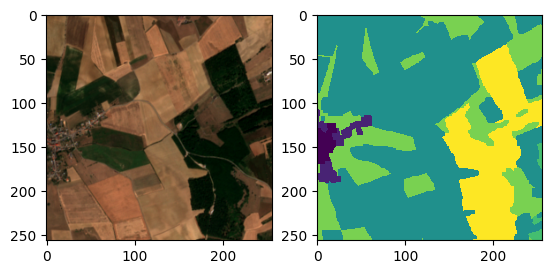

In [26]:
env = lmdb.open(fp_lmdb, readonly=True)
with env.begin() as txn:
    obj = txn.get(str(8156).encode())
    img_bytes, img_shape, lbl_bytes, lbl_shape, name = pickle.loads(obj)
    img = np.frombuffer(img_bytes, dtype=np.uint16).reshape(img_shape)
    lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape)
print(name.decode())
plt.figure()
plt.subplot(121)
img_show = img[[2,1,0]].transpose(1,2,0)
img_show = (img_show - np.min(img_show))/(np.max(img_show) - np.min(img_show))
plt.imshow(img_show)
plt.subplot(122)
plt.imshow(lbl.squeeze(), interpolation='none')

- split training and test sets

In [4]:
fd = '/home/chenying/data/weakFT'
fp = '/home/chenying/data/weakFT/test/multisenge.lmdb'
env_src = lmdb.open(fp, readonly=True)
txn_src = env_src.begin()
n = txn_src.stat()['entries']

n_ts = 4000
n_tr = n - n_ts
inds = np.arange(n)
inds_tr = np.random.choice(inds, n_tr, replace=False)
inds_ts = np.setdiff1d(inds, inds_tr)
for split, inds in zip(['train', 'test'], [inds_tr, inds_ts]):
    pdir = split if split == 'test' else 'ft_train'
    fp = os.path.join(fd, pdir, f'multisenge_{split}.lmdb')
    env = lmdb.open(fp, map_size=int(5.5*1024**3))
    txn = env.begin(write=True)
    for i, ind in tqdm(enumerate(inds)):
        obj = txn_src.get(str(ind).encode())
        txn.put(str(i).encode(), obj)
    txn.commit()
    env.sync()
    env.close()

4157it [00:02, 1602.15it/s]
4000it [00:02, 1716.98it/s]


train: 4157
train: 4157, 31UFQ_20200805_S2_8995_9252.tif
test: 4000
test: 4000, 31UFQ_20200721_S2_7967_7453.tif


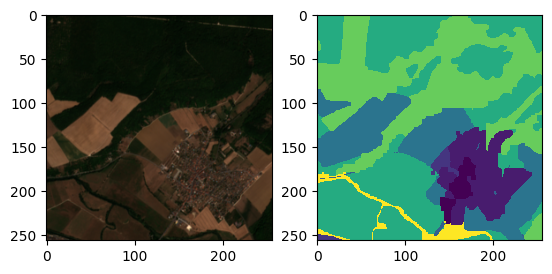

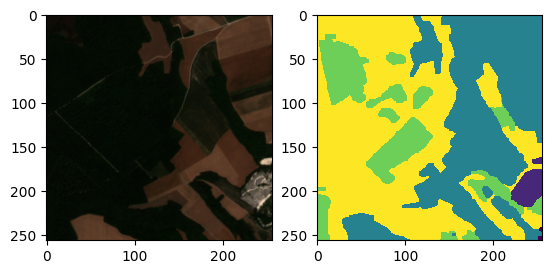

In [9]:
i = 2900
for split, inds in zip(['train', 'test'], [inds_tr, inds_ts]):
    pdir = split if split == 'test' else 'ft_train'
    fp = os.path.join(fd, pdir, f'multisenge_{split}.lmdb')
    env = lmdb.open(fp, readonly=True)
    with env.begin() as txn:
        n = txn.stat()['entries']
        print(f'{split}: {n}')
        data = txn.get(str(i).encode())
        img_bytes, img_shape, lbl_bytes, lbl_shape, name = pickle.loads(data)
        img = np.frombuffer(img_bytes, dtype=np.uint16).reshape(img_shape)
        lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape)
        print(f'{split}: {n}, {name.decode()}')
        plt.figure()
        plt.subplot(121)
        img_show = img[[2,1,0]].transpose(1,2,0)
        img_show = (img_show - np.min(img_show))/(np.max(img_show) - np.min(img_show))
        plt.imshow(img_show)
        plt.subplot(122)
        plt.imshow(lbl.squeeze(), interpolation='none')
    env.close()


# LoveDA

((1024, 1024),
 array([1, 2, 3, 4, 6], dtype=uint8),
 (1024, 1024, 3),
 dtype('uint8'))

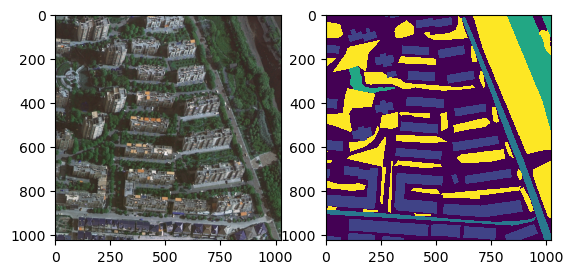

In [43]:
ind = 3602
fp_img = f'/home/chenying/data/weakFT/test_zips/LoveDA/Val/Urban/images_png/{ind}.png'
fp_lbl = f'/home/chenying/data/weakFT/test_zips/LoveDA/Val/Urban/masks_png/{ind}.png'
img = cv2.imread(fp_img)
lbl = cv2.imread(fp_lbl, cv2.IMREAD_GRAYSCALE)
plt.figure()
plt.subplot(121)
plt.imshow(img)
plt.subplot(122)
plt.imshow(lbl, interpolation='none')
lbl.shape, np.unique(lbl), img.shape, img.dtype

In [42]:
!ls /home/chenying/data/weakFT/test_zips/LoveDA/Val/Urban/images_png

3514.png  3599.png  3684.png  3769.png	3854.png  3939.png  4024.png  4109.png
3515.png  3600.png  3685.png  3770.png	3855.png  3940.png  4025.png  4110.png
3516.png  3601.png  3686.png  3771.png	3856.png  3941.png  4026.png  4111.png
3517.png  3602.png  3687.png  3772.png	3857.png  3942.png  4027.png  4112.png
3518.png  3603.png  3688.png  3773.png	3858.png  3943.png  4028.png  4113.png
3519.png  3604.png  3689.png  3774.png	3859.png  3944.png  4029.png  4114.png
3520.png  3605.png  3690.png  3775.png	3860.png  3945.png  4030.png  4115.png
3521.png  3606.png  3691.png  3776.png	3861.png  3946.png  4031.png  4116.png
3522.png  3607.png  3692.png  3777.png	3862.png  3947.png  4032.png  4117.png
3523.png  3608.png  3693.png  3778.png	3863.png  3948.png  4033.png  4118.png
3524.png  3609.png  3694.png  3779.png	3864.png  3949.png  4034.png  4119.png
3525.png  3610.png  3695.png  3780.png	3865.png  3950.png  4035.png  4120.png
3526.png  3611.png  3696.png  3781.png	3866.png  3951.png  4036.

## save small patches of 256x256

In [11]:
def save_to_lmdb(fp_lmdb, img_dir_, lbl_dir_, GB_size=7, p=256):
    env = lmdb.open(fp_lmdb, map_size=int(GB_size*1024**3))
    txn = env.begin(write=True)
    idx = 0

    for sub_dir in ['Urban', 'Rural']:
        img_dir = os.path.join(img_dir_, sub_dir, 'images_png')
        lbl_dir = os.path.join(lbl_dir_, sub_dir, 'masks_png')
        for img_name in tqdm(os.listdir(img_dir), desc=sub_dir):
            if img_name.endswith('.png'):
                img_path = os.path.join(img_dir, img_name)
                lbl_path = os.path.join(lbl_dir, img_name)

                img = cv2.imread(img_path).transpose(2, 0, 1)
                lbl = cv2.imread(lbl_path, cv2.IMREAD_GRAYSCALE)

                _, h, w = img.shape
                for i in range(0, h-p+1, p):
                    for j in range(0, w-p+1, p):
                        img_crop = img[:, i:i+p, j:j+p]
                        lbl_crop = lbl[i:i+p, j:j+p]

                        img_ind = f'{sub_dir}_{img_name.split(".")[0]}_{i}_{j}'
                        key = str(idx).encode()
                        obj = (img_crop.tobytes(), img_crop.shape, lbl_crop.tobytes(), lbl_crop.shape, img_ind.encode())
                        txn.put(key, pickle.dumps(obj))
                        idx += 1

    txn.commit()
    env.sync()
    env.close()
    print(f'Finish saving {idx} samples to {fp_lmdb}')

In [13]:
for p in [128, 512]:
    fp_lmdb = f'/home/chenying/data/weakFT/test/loveda_p{p}_val.lmdb'
    img_dir_ = '/home/chenying/data/weakFT/test_zips/LoveDA/Val'
    lbl_dir_ = '/home/chenying/data/weakFT/test_zips/LoveDA/Val'

    save_to_lmdb(fp_lmdb, img_dir_, lbl_dir_, GB_size=7, p=p)

Rural: 100%|██████████| 992/992 [00:55<00:00, 17.87it/s]


Finish saving 106816 samples to /home/chenying/data/weakFT/test/loveda_p128_val.lmdb


Rural: 100%|██████████| 992/992 [00:55<00:00, 17.76it/s]


Finish saving 6676 samples to /home/chenying/data/weakFT/test/loveda_p512_val.lmdb


In [28]:
fp_lmdb = '/home/chenying/data/weakFT/test/loveda_p256_val.lmdb'
img_dir_ = '/home/chenying/data/weakFT/test_zips/LoveDA/Val'
lbl_dir_ = '/home/chenying/data/weakFT/test_zips/LoveDA/Val'

save_to_lmdb(fp_lmdb, img_dir_, lbl_dir_, GB_size=7)

Rural: 100%|██████████| 992/992 [00:55<00:00, 17.79it/s]


Finish saving 26704 samples to /home/chenying/data/weakFT/test/loveda_p256_val.lmdb


In [31]:
fp_lmdb = '/home/chenying/data/weakFT/ft_train/loveda_p256_train.lmdb'
img_dir_ = '/home/chenying/data/weakFT/test_zips/LoveDA/Train'
lbl_dir_ = '/home/chenying/data/weakFT/test_zips/LoveDA/Train'

save_to_lmdb(fp_lmdb, img_dir_, lbl_dir_, GB_size=10.5)

Rural: 100%|██████████| 1366/1366 [01:19<00:00, 17.14it/s]


Finish saving 40352 samples to /home/chenying/data/weakFT/ft_train/loveda_p256_train.lmdb


16429 Urban_4083_0_0


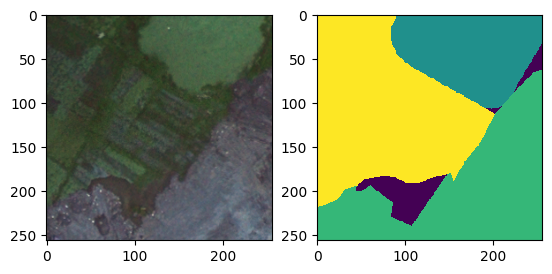

In [62]:
fp_lmdb_val = '/home/chenying/data/weakFT/test/loveda_val.lmdb'
env_val = lmdb.open(fp_lmdb_val, readonly=True)
with env_val.begin() as txn:
    n_val = txn.stat()['entries']
    img_bytes, img_shape, lbl_bytes, lbl_shape, img_ind = pickle.loads(txn.get(str(10).encode()))
    img = np.frombuffer(img_bytes, dtype=np.uint8).reshape(img_shape)
    lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape)
    print(n_val, img_ind.decode())
    plt.figure()
    plt.subplot(121)
    plt.imshow(img.transpose(1,2,0))
    plt.subplot(122)
    plt.imshow(lbl, interpolation='none')
    

31693 Rural_1353_768_768


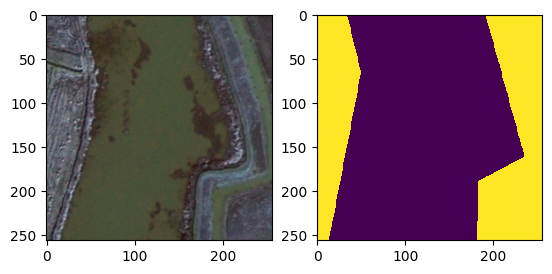

In [ ]:
i = 31692
fp_lmdb_tr = '/home/chenying/data/weakFT/ft_train/loveda_train.lmdb'
env_tr = lmdb.open(fp_lmdb_tr, readonly=True)
with env_tr.begin() as txn:
    n_tr = txn.stat()['entries']
    img_bytes, img_shape, lbl_bytes, lbl_shape, img_ind = pickle.loads(txn.get(str(i).encode()))
    img = np.frombuffer(img_bytes, dtype=np.uint8).reshape(img_shape)
    lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape)
    print(n_tr, img_ind.decode())
    plt.figure()
    plt.subplot(121)
    plt.imshow(img.transpose(1,2,0))
    plt.subplot(122)
    plt.imshow(lbl, interpolation='none')

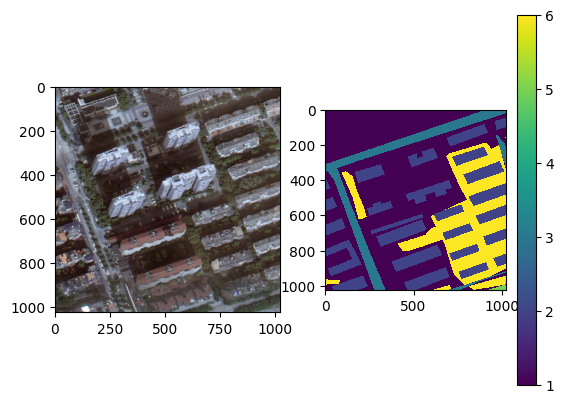

In [17]:
fp = '/home/chenying/data/weakFT/test_zips/LoveDA/Train/Urban/masks_png/2268.png'
fp_img = '/home/chenying/data/weakFT/test_zips/LoveDA/Train/Urban/images_png/2268.png'
img = cv2.imread(fp_img)
lbl = cv2.imread(fp, cv2.IMREAD_GRAYSCALE)
np.unique(lbl)
plt.figure()
plt.subplot(121)
plt.imshow(img)
plt.subplot(122)
plt.imshow(lbl, interpolation='none')
plt.colorbar()

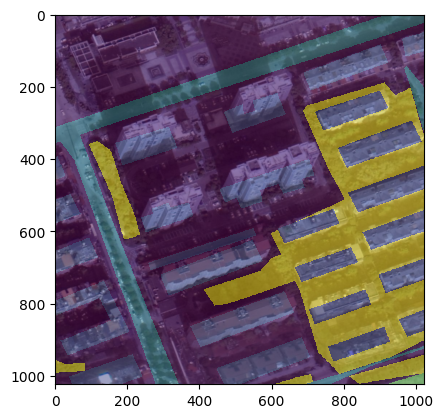

In [80]:
plt.figure()
plt.imshow(img)
plt.imshow(lbl, interpolation='none', alpha=0.5)

## save big patches

In [73]:
def save_to_lmdb(fp_lmdb, img_dir_, lbl_dir_, GB_size=7):
    env = lmdb.open(fp_lmdb, map_size=GB_size*1024**3)
    txn = env.begin(write=True)
    idx = 0

    for sub_dir in ['Urban', 'Rural']:
        img_dir = os.path.join(img_dir_, sub_dir, 'images_png')
        lbl_dir = os.path.join(lbl_dir_, sub_dir, 'masks_png')
        for img_name in tqdm(os.listdir(img_dir), desc=sub_dir):
            if img_name.endswith('.png'):
                img_path = os.path.join(img_dir, img_name)
                lbl_path = os.path.join(lbl_dir, img_name)

                img = cv2.imread(img_path).transpose(2, 0, 1)
                lbl = cv2.imread(lbl_path, cv2.IMREAD_GRAYSCALE)

                img_ind = f'{sub_dir}_{img_name.split(".")[0]}'
                key = str(idx).encode()
                obj = (img.tobytes(), img.shape, lbl.tobytes(), lbl.shape, img_ind.encode())
                txn.put(key, pickle.dumps(obj))
                idx += 1

    txn.commit()
    env.sync()
    env.close()
    print(f'Finish saving {idx} samples to {fp_lmdb}')

In [ ]:
fp_lmdb = '/home/chenying/data/weakFT/test/loveda_p1024_val.lmdb'
img_dir_ = '/home/chenying/data/weakFT/test_zips/LoveDA/Val'
lbl_dir_ = '/home/chenying/data/weakFT/test_zips/LoveDA/Val'

save_to_lmdb(fp_lmdb, img_dir_, lbl_dir_)

Rural: 100%|██████████| 992/992 [00:50<00:00, 19.83it/s]


Finish saving 1669 samples to /home/chenying/data/weakFT/test/loveda_origin_val.lmdb


In [ ]:
fp_lmdb = '/home/chenying/data/weakFT/ft_train/loveda_p1024_train.lmdb'
img_dir_ = '/home/chenying/data/weakFT/test_zips/LoveDA/Train'
lbl_dir_ = '/home/chenying/data/weakFT/test_zips/LoveDA/Train'

save_to_lmdb(fp_lmdb, img_dir_, lbl_dir_, GB_size=10)

Rural: 100%|██████████| 1366/1366 [01:09<00:00, 19.56it/s]


Finish saving 2522 samples to /home/chenying/data/weakFT/ft_train/loveda_origin_train.lmdb


2522 Urban_2436


array([1, 2, 3, 6], dtype=uint8)

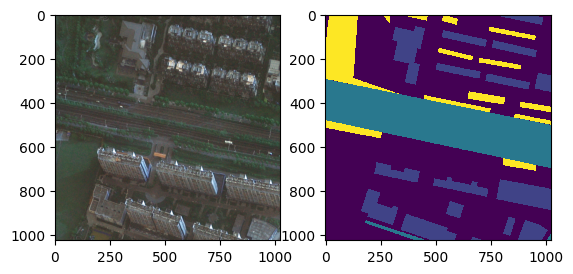

In [26]:
i = 42
fp_lmdb_tr = '/home/chenying/data/weakFT/ft_train/loveda_p1024_train.lmdb'
env_tr = lmdb.open(fp_lmdb_tr, readonly=True)
with env_tr.begin() as txn:
    n_tr = txn.stat()['entries']
    img_bytes, img_shape, lbl_bytes, lbl_shape, img_ind = pickle.loads(txn.get(str(i).encode()))
    img = np.frombuffer(img_bytes, dtype=np.uint8).reshape(img_shape)
    lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape)
    print(n_tr, img_ind.decode())
    plt.figure()
    plt.subplot(121)
    plt.imshow(img.transpose(1,2,0))
    plt.subplot(122)
    plt.imshow(lbl, interpolation='none')
np.unique(lbl)

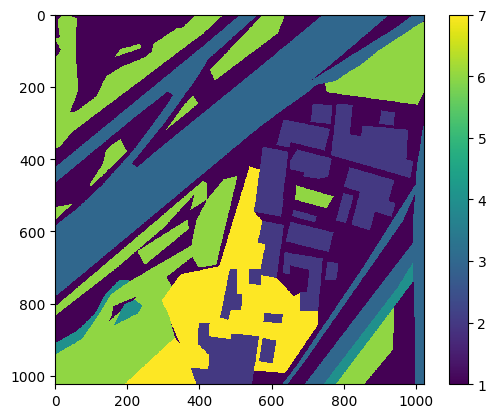

In [7]:
plt.figure()
plt.imshow(lbl, interpolation='none')
plt.colorbar()

# Vaihingen

(2569, 1919) [0 2 3 4 6 9]


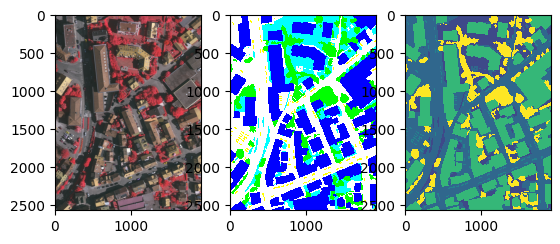

In [47]:
aid = 1
fp_img = os.path.join('/home/chenying/data/weakFT/test_zips/isprs/vaihingen/top', f'top_mosaic_09cm_area{aid}.tif')
fp_lbl = os.path.join('/home/chenying/data/weakFT/test_zips/isprs/vaihingen/gts_for_participants', f'top_mosaic_09cm_area{aid}.tif')
with rasterio.open(fp_img, 'r') as src:
    img = src.read()
with rasterio.open(fp_lbl, 'r') as src:
    lbl = src.read()

# Define the RGB to label mapping
rgb_to_label = {
    (255, 255, 125): 1,  # Powerline
    (0, 255, 255): 2,    # Low vegetation
    (255, 255, 255): 3,  # Impervious surfaces
    (255, 255, 0): 4,    # Car
    (0, 255, 125): 5,    # Fence/Hedge
    (0, 0, 255): 6,      # Roof
    (0, 125, 255): 7,    # Facade
    (125, 255, 0): 8,    # Shrub
    (0, 255, 0): 9       # Tree
}

plt.figure()
plt.subplot(131)
plt.imshow(img.transpose(1,2,0))
plt.subplot(132)
plt.imshow(lbl.transpose(1,2,0), interpolation='none')
lbl_ = lbl.transpose(1,2,0)
# Create an empty one-channel image for the labels
label_img = np.zeros((lbl_.shape[0], lbl_.shape[1]), dtype=np.uint8)

# Iterate over the RGB to label mapping and apply the labels
for rgb, label in rgb_to_label.items():
    mask = np.all(lbl_ == rgb, axis=-1)
    label_img[mask] = label
plt.subplot(133)
plt.imshow(label_img, interpolation='none')
# plt.colorbar()
print(label_img.shape, np.unique(label_img))

- proportions of each class

In [ ]:
lbl_dir = '/home/chenying/data/weakFT/test_zips/isprs/vaihingen/gts_for_participants'
fns = os.listdir(lbl_dir)
n_cls = np.zeros(10, dtype=int)
n_all = 0
for f in tqdm(fns, total=len(fns)):
    fp_lbl = os.path.join(lbl_dir, f)
    with rasterio.open(fp_lbl, 'r') as src:
        lbl = src.read()

    # Define the RGB to label mapping (official codes)
    rgb_to_label = {
        (255, 255, 125): 1,  # Powerline
        (0, 255, 255): 2,    # Low vegetation
        (255, 255, 255): 3,  # Impervious surfaces
        (255, 255, 0): 4,    # Car
        (0, 255, 125): 5,    # Fence/Hedge
        (0, 0, 255): 6,      # Roof
        (0, 125, 255): 7,    # Facade
        (125, 255, 0): 8,    # Shrub
        (0, 255, 0): 9       # Tree
    }

    lbl_ = lbl.transpose(1,2,0)
    # Create an empty one-channel image for the labels
    label_img = np.zeros((lbl_.shape[0], lbl_.shape[1]), dtype=np.uint8)
    n_all += lbl_.shape[0]*lbl_.shape[1]

    # Iterate over the RGB to label mapping and apply the labels
    for rgb, label in rgb_to_label.items():
        mask = np.all(lbl_ == rgb, axis=-1)
        label_img[mask] = label
    
    for c in range(10):
        n_ = (label_img==c).sum()
        n_cls[c] += n_

print(n_cls, n_all, np.sum(n_cls))
print(n_cls/n_all)

  0%|          | 0/33 [00:00<?, ?it/s]/home/chenying/myenvs/miniconda3/envs/sam2/lib/python3.12/site-packages/rasterio/__init__.py:304: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
100%|██████████| 33/33 [00:04<00:00,  7.59it/s]

[ 1317670        0 35766767 46792757  2096078        0 43779851        0
        0 38534748] 168287871 168287871
[0.00782986 0.         0.21253324 0.27805187 0.01245531 0.
 0.26014858 0.         0.         0.22898114]


- mmseg splits and label codes

In [34]:
splits = {
        'train': [
            'area1', 'area11', 'area13', 'area15', 'area17', 'area21',
            'area23', 'area26', 'area28', 'area3', 'area30', 'area32',
            'area34', 'area37', 'area5', 'area7'
        ],
        'val': [
            'area6', 'area24', 'area35', 'area16', 'area14', 'area22',
            'area10', 'area4', 'area2', 'area20', 'area8', 'area31', 'area33',
            'area27', 'area38', 'area12', 'area29'
        ],
    }

# Define the RGB to label mapping
label_codes = {
    (0, 255, 255): 1,    # Low vegetation
    (255, 255, 255): 2,  # Impervious surfaces
    (255, 255, 0): 3,    # Car
    (0, 0, 255): 4,      # Roof
    (0, 255, 0): 5       # Tree
}
# the others would be assigned to 0 as background/clutter

- save small patches of size of 256x256

In [38]:
def save_to_lmdb(fp_lmdb, fd_img, split, crop_size=256, GB_size=7):
    env = lmdb.open(fp_lmdb, map_size=int(GB_size*1024**3))
    txn = env.begin(write=True)
    idx = 0

    split_ids = splits[split]
    for area_id in tqdm(split_ids, desc=split):
        img_path = os.path.join(fd_img, 'top', f'top_mosaic_09cm_{area_id}.tif')
        lbl_path = os.path.join(fd_img, 'gts_for_participants', f'top_mosaic_09cm_{area_id}.tif')

        with rasterio.open(img_path, 'r') as src:
            img = src.read()
        with rasterio.open(lbl_path, 'r') as src:
            lbl = src.read().transpose(1,2,0)   

        # convert labels
        label_img = np.zeros((lbl.shape[0], lbl.shape[1]), dtype=np.uint8)
        for rgb, label in label_codes.items():
            mask = np.all(lbl == rgb, axis=-1)
            label_img[mask] = label
        
        _, h, w = img.shape
        for i in range(0, h, crop_size):
            for j in range(0, w, crop_size):
                if i+crop_size > h or j+crop_size > w: continue
                img_crop = img[:, i:i+crop_size, j:j+crop_size]
                lbl_crop = label_img[i:i+crop_size, j:j+crop_size]

                img_ind = f'{area_id}_{i}_{j}'
                key = str(idx).encode()
                obj = (img_crop.tobytes(), img_crop.shape, lbl_crop.tobytes(), lbl_crop.shape, img_ind.encode())
                txn.put(key, pickle.dumps(obj))
                idx += 1

    txn.commit()
    env.sync()
    env.close()
    print(f'Finish saving {idx} samples to {fp_lmdb}')

In [40]:
fd_img = '/home/chenying/data/weakFT/test_zips/isprs/vaihingen'
fd_lmdb = '/home/chenying/data/weakFT'
for split, gs in zip(['train', 'val'], [0.3, 0.35]):
    if split == 'val':
        fp_lmdb = os.path.join(fd_lmdb, 'test', f'vaihingen_p256_{split}.lmdb')
    else:
        fp_lmdb = os.path.join(fd_lmdb, 'ft_train', f'vaihingen_p256_{split}.lmdb')
    save_to_lmdb(fp_lmdb, fd_img, split, crop_size=256, GB_size=gs)

train: 100%|██████████| 16/16 [00:02<00:00,  5.64it/s]


Finish saving 1046 samples to /home/chenying/data/weakFT/ft_train/vaihingen_p256_train.lmdb


val: 100%|██████████| 17/17 [00:03<00:00,  5.04it/s]


Finish saving 1208 samples to /home/chenying/data/weakFT/test/vaihingen_p256_val.lmdb


1514 area31_2048_512


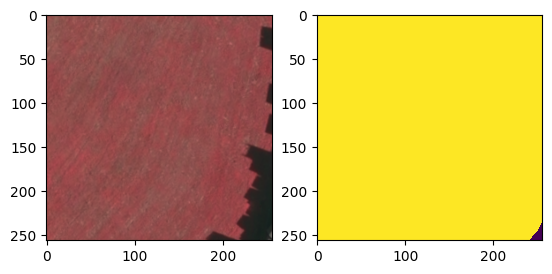

In [15]:
i = 1000
fd_lmdb = '/home/chenying/data/weakFT'
split = 'val'
fp_lmdb = os.path.join(fd_lmdb, 'test', f'vaihingen_p256_{split}.lmdb')
with lmdb.open(fp_lmdb, readonly=True) as env:
    with env.begin() as txn:
        n = txn.stat()['entries']
        img_bytes, img_shape, lbl_bytes, lbl_shape, img_ind = pickle.loads(txn.get(str(i).encode()))
        img = np.frombuffer(img_bytes, dtype=np.uint8).reshape(img_shape)
        lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape)
        print(n, img_ind.decode())
        plt.figure()
        plt.subplot(121)
        plt.imshow(img.transpose(1,2,0))
        plt.subplot(122)
        plt.imshow(lbl, interpolation='none')

In [15]:
imgs = []
for split, gs in zip(['train', 'val'], [0.3, 0.35]):
    if split == 'val':
        fp_lmdb = os.path.join(fd_lmdb, 'test', f'vaihingen_p256_{split}.lmdb')
    else:
        fp_lmdb = os.path.join(fd_lmdb, 'ft_train', f'vaihingen_p256_{split}.lmdb')
    env = lmdb.open(fp_lmdb, readonly=True)
    with env.begin() as txn:
        n = txn.stat()['entries']
        print(f'{split}: {n}')
        for i in range(n):
            data = txn.get(str(i).encode())
            img_bytes, img_shape, lbl_bytes, lbl_shape, img_ind = pickle.loads(data)
            img = np.frombuffer(img_bytes, dtype=np.uint8).reshape(img_shape)
            imgs.append(img)

imgs = np.stack(imgs, axis=-1)
print(imgs.shape)
imgs.mean(axis=(1,2,3)), imgs.std(axis=(1,2,3))

train: 1046
val: 1208
(3, 256, 256, 2254)


(array([120.37964902,  81.69096275,  81.1528849 ]),
 array([54.81693005, 39.22888647, 37.89783003]))

# Potsdam: RGB-NIR

/home/chenying/myenvs/miniconda3/envs/sam2/lib/python3.12/site-packages/rasterio/__init__.py:304: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)


[  0 255] [  0 255]


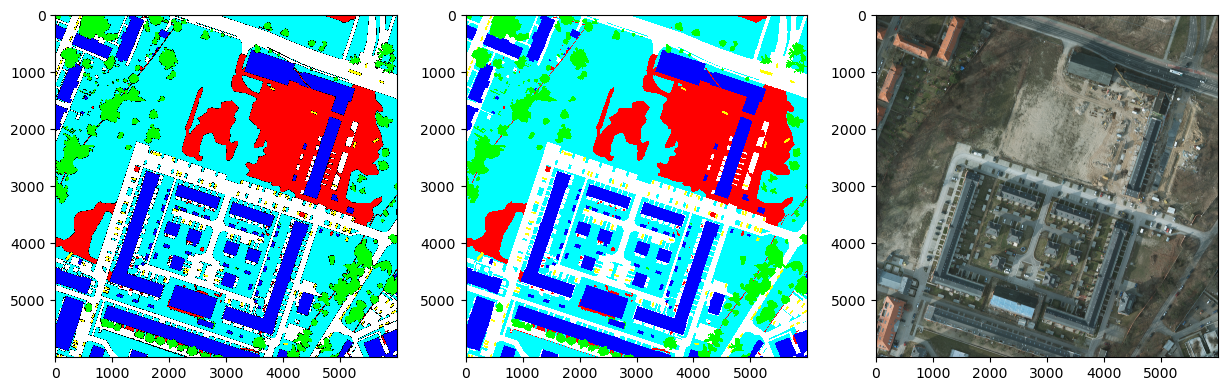

In [14]:
fp = '/home/chenying/data/weakFT/test_zips/Potsdam/4_Ortho_RGBIR/top_potsdam_2_10_RGBIR.tif'
fp_nb = '/home/chenying/data/weakFT/test_zips/Potsdam/labels_nob/top_potsdam_2_10_label_noBoundary.tif'
fp_lbl = '/home/chenying/data/weakFT/test_zips/Potsdam/labels_all/top_potsdam_2_10_label.tif'
with rasterio.open(fp) as src:
    img = src.read()
with rasterio.open(fp_nb) as src:
    lbl_nb = src.read()
with rasterio.open(fp_lbl) as src:
    lbl = src.read()
print(np.unique(lbl_nb), np.unique(lbl))
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(lbl_nb.transpose(1,2,0), interpolation='none')
plt.subplot(132)
plt.imshow(lbl.transpose(1,2,0), interpolation='none')
plt.subplot(133)
plt.imshow(img[:3].transpose(1,2,0))

In [15]:
splits = {
        'train': [
            '2_10', '2_11', '2_12', '3_10', '3_11', '3_12', '4_10', '4_11',
            '4_12', '5_10', '5_11', '5_12', '6_10', '6_11', '6_12', '6_7',
            '6_8', '6_9', '7_10', '7_11', '7_12', '7_7', '7_8', '7_9'
        ],
        'val': [
            '5_15', '6_15', '6_13', '3_13', '4_14', '6_14', '5_14', '2_13',
            '4_15', '2_14', '5_13', '4_13', '3_14', '7_13'
        ]
    }

# Define the RGB to label mapping
label_codes = {
    (0, 255, 255): 1,    # Low vegetation
    (255, 255, 255): 2,  # Impervious surfaces
    (255, 255, 0): 3,    # Car
    (0, 0, 255): 4,      # Roof
    (0, 255, 0): 5       # Tree
}
# the others would be assigned to 0 as background/clutter


In [42]:
fd_img = '/home/chenying/data/weakFT/test_zips/Potsdam'

def get_patch_num(fd_img, split, crop_size=256):
    idx = 0

    split_ids = splits[split]
    for area_id in split_ids:
        img_path = os.path.join(fd_img, '4_Ortho_RGBIR', f'top_potsdam_{area_id}_RGBIR.tif')
        
        with rasterio.open(img_path, 'r') as src:
            img = src.read()
        
        _, h, w = img.shape
        for i in range(0, h, crop_size):
            for j in range(0, w, crop_size):
                if i+crop_size > h or j+crop_size > w: continue
                idx += 1

    print(f'Finish saving {idx} {split} samples to {fp_lmdb}')

for ps in [256, 512, 1024]:
    print(f'crop_size: {ps}')
    for split, gs in zip(['train', 'val'], [0.4, 0.4]):
        get_patch_num(fd_img, split, crop_size=ps)

crop_size: 256
Finish saving 12696 train samples to /home/chenying/data/weakFT/test/vaihingen_p256_val.lmdb
Finish saving 7406 val samples to /home/chenying/data/weakFT/test/vaihingen_p256_val.lmdb
crop_size: 512
Finish saving 2904 train samples to /home/chenying/data/weakFT/test/vaihingen_p256_val.lmdb
Finish saving 1694 val samples to /home/chenying/data/weakFT/test/vaihingen_p256_val.lmdb
crop_size: 1024
Finish saving 600 train samples to /home/chenying/data/weakFT/test/vaihingen_p256_val.lmdb
Finish saving 350 val samples to /home/chenying/data/weakFT/test/vaihingen_p256_val.lmdb


In [46]:
12696*256*256*5/1024**3, 7406*256*256*5/1024**3, 2904*512*512*5/1024**3, 1696*512*512*5/1024**3

(3.87451171875, 2.2601318359375, 3.544921875, 2.0703125)

In [16]:
def save_to_lmdb(fp_lmdb, fd_img, split, crop_size=256, GB_size=7):
    env = lmdb.open(fp_lmdb, map_size=int(GB_size*1024**3))
    txn = env.begin(write=True)
    idx = 0

    split_ids = splits[split]
    for area_id in tqdm(split_ids, desc=split):
        img_path = os.path.join(fd_img, '4_Ortho_RGBIR', f'top_potsdam_{area_id}_RGBIR.tif')
        lbl_path = os.path.join(fd_img, 'labels_all', f'top_potsdam_{area_id}_label.tif')

        with rasterio.open(img_path, 'r') as src:
            img = src.read()
        with rasterio.open(lbl_path, 'r') as src:
            lbl = src.read().transpose(1,2,0)   

        # convert labels
        label_img = np.zeros((lbl.shape[0], lbl.shape[1]), dtype=np.uint8)
        for rgb, label in label_codes.items():
            mask = np.all(lbl == rgb, axis=-1)
            label_img[mask] = label
        
        _, h, w = img.shape
        for i in range(0, h, crop_size):
            for j in range(0, w, crop_size):
                if i+crop_size > h or j+crop_size > w: continue
                img_crop = img[:, i:i+crop_size, j:j+crop_size]
                lbl_crop = label_img[i:i+crop_size, j:j+crop_size]

                img_ind = f'{area_id}_{i}_{j}'
                key = str(idx).encode()
                obj = (img_crop.tobytes(), img_crop.shape, lbl_crop.tobytes(), lbl_crop.shape, img_ind.encode())
                txn.put(key, pickle.dumps(obj))
                idx += 1

    txn.commit()
    env.sync()
    env.close()
    print(f'Finish saving {idx} samples to {fp_lmdb}')

In [18]:
fd_img = '/home/chenying/data/weakFT/test_zips/Potsdam'
fd_lmdb = '/home/chenying/data/weakFT'
for patch_size in [256, 128, 2048]:
    for split, gs in zip(['val'], [2.5]):
        if split == 'val':
            fp_lmdb = os.path.join(fd_lmdb, 'test', f'potsdam_p{patch_size}_{split}.lmdb')
        else:
            fp_lmdb = os.path.join(fd_lmdb, 'ft_train', f'potsdam_p{patch_size}_{split}.lmdb')
        save_to_lmdb(fp_lmdb, fd_img, split, crop_size=patch_size, GB_size=gs)

val: 100%|██████████| 14/14 [00:23<00:00,  1.65s/it]


Finish saving 7406 samples to /home/chenying/data/weakFT/test/potsdam_p256_val.lmdb


val: 100%|██████████| 14/14 [00:22<00:00,  1.63s/it]


Finish saving 29624 samples to /home/chenying/data/weakFT/test/potsdam_p128_val.lmdb


val: 100%|██████████| 14/14 [00:26<00:00,  1.86s/it]


Finish saving 56 samples to /home/chenying/data/weakFT/test/potsdam_p2048_val.lmdb


In [10]:
fd_img = '/home/chenying/data/weakFT/test_zips/Potsdam'
fd_lmdb = '/home/chenying/data/weakFT'
patch_size = 1024
for split, gs in zip(['train', 'val'], [4, 2.5]):
    if split == 'val':
        fp_lmdb = os.path.join(fd_lmdb, 'test', f'potsdam_p{patch_size}_{split}.lmdb')
    else:
        fp_lmdb = os.path.join(fd_lmdb, 'ft_train', f'potsdam_p{patch_size}_{split}.lmdb')
    save_to_lmdb(fp_lmdb, fd_img, split, crop_size=patch_size, GB_size=gs)

train: 100%|██████████| 24/24 [00:35<00:00,  1.48s/it]


Finish saving 600 samples to /home/chenying/data/weakFT/ft_train/potsdam_p1024_train.lmdb


val: 100%|██████████| 14/14 [00:42<00:00,  3.01s/it]


Finish saving 350 samples to /home/chenying/data/weakFT/test/potsdam_p1024_val.lmdb


In [2]:
fd_lmdb = '/home/chenying/data/weakFT'
patch_size = 512
imgs = []
for split, gs in zip(['train', 'val'], [5, 3]):
    if split == 'val':
        fp_lmdb = os.path.join(fd_lmdb, 'test', f'potsdam_p{patch_size}_{split}.lmdb')
    else:
        fp_lmdb = os.path.join(fd_lmdb, 'ft_train', f'potsdam_p{patch_size}_{split}.lmdb')
    with lmdb.open(fp_lmdb, readonly=True) as env:
        n = env.stat()['entries']
        with env.begin() as txn:
            for i in range(n):
                img_bytes, img_shape, lbl_bytes, lbl_shape, img_ind = pickle.loads(txn.get(str(i).encode()))
                img = np.frombuffer(img_bytes, dtype=np.uint8).reshape(img_shape)
                imgs.append(img)
imgs_all = np.stack(imgs, axis=-1)
imgs_all.shape

(4, 512, 512, 4598)

In [49]:
img_mean = np.mean(imgs_all, axis=(1,2,3))
img_std = np.std(imgs_all, axis=(1,2,3))
img_mean, img_std

(array([86.76148954, 92.73532149, 86.09950501, 97.83588164]),
 array([35.85052416, 35.41563606, 36.80779508, 36.24292287]))

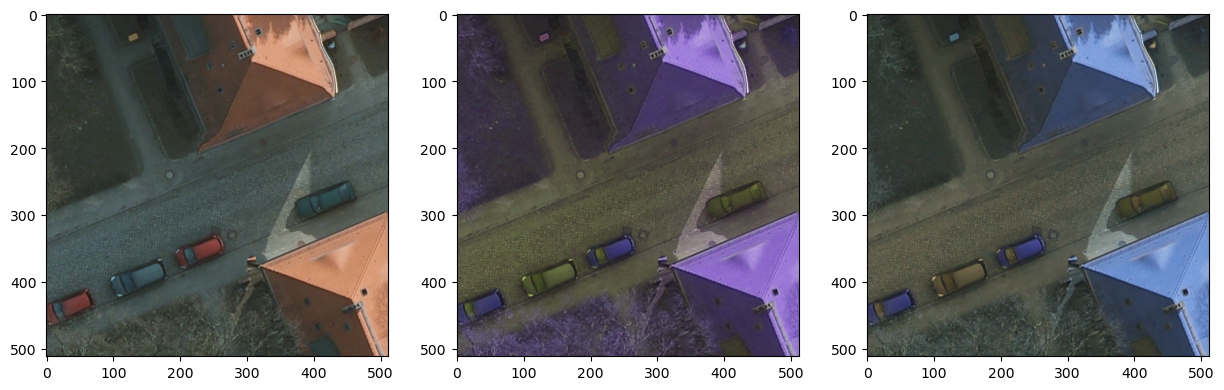

In [4]:
i = 0 
img = imgs_all[:,:,:,i].T
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(img[:,:,:3])
plt.subplot(132)
plt.imshow(img[:,:,1:])
plt.subplot(133)
plt.imshow(img[:,:,[2,1,0]])


# Five-billion-pixels: bands order is NIR-RGB

In [4]:
fd = '/home/chenying/data/weakFT/test_zips/FiveBillionImages'
fns = os.listdir(fd)
i = 20

20 (6908, 7300, 4) (6908, 7300) [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 17 18 19 20 21 22 23 24]


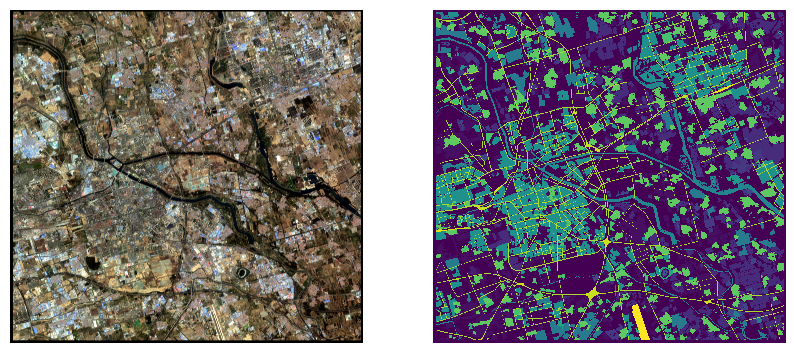

In [5]:
fp_img = f'/home/chenying/data/weakFT/test_zips/FiveBillionImages/{fns[i]}'
fp_lbl = f'/home/chenying/data/weakFT/test_zips/FiveBillionLabels/{fns[i][:-4]}_24label.png'
img = np.array(Image.open(fp_img).convert('CMYK'))
lbl = cv2.imread(fp_lbl, cv2.IMREAD_GRAYSCALE)
print(i, img.shape, lbl.shape, np.unique(lbl))
plt.figure(figsize=(10,5))
plt.subplot(121)
plt.imshow(img[:,:,1:])
plt.axis('off')
plt.subplot(122)
plt.imshow(lbl, interpolation='none')
plt.axis('off')
i+=1

In [6]:
test_files = ['GF2_PMS1__L1A0001064454-MSS1.tif',
              'GF2_PMS1__L1A0001118839-MSS1.tif',
              'GF2_PMS1__L1A0001344822-MSS1.tif',
              'GF2_PMS1__L1A0001348919-MSS1.tif',
              'GF2_PMS1__L1A0001366278-MSS1.tif',
              'GF2_PMS1__L1A0001366284-MSS1.tif',
              'GF2_PMS1__L1A0001395956-MSS1.tif',
              'GF2_PMS1__L1A0001432972-MSS1.tif',
              'GF2_PMS1__L1A0001670888-MSS1.tif',
              'GF2_PMS1__L1A0001680857-MSS1.tif',
              'GF2_PMS1__L1A0001680858-MSS1.tif',
              'GF2_PMS1__L1A0001757429-MSS1.tif',
              'GF2_PMS1__L1A0001765574-MSS1.tif',
              'GF2_PMS2__L1A0000607677-MSS2.tif',
              'GF2_PMS2__L1A0000607681-MSS2.tif',
              'GF2_PMS2__L1A0000718813-MSS2.tif',
              'GF2_PMS2__L1A0001038935-MSS2.tif',
              'GF2_PMS2__L1A0001038936-MSS2.tif',
              'GF2_PMS2__L1A0001119060-MSS2.tif',
              'GF2_PMS2__L1A0001367840-MSS2.tif',
              'GF2_PMS2__L1A0001378491-MSS2.tif',
              'GF2_PMS2__L1A0001378501-MSS2.tif',
              'GF2_PMS2__L1A0001396036-MSS2.tif',
              'GF2_PMS2__L1A0001396037-MSS2.tif',
              'GF2_PMS2__L1A0001416129-MSS2.tif',
              'GF2_PMS2__L1A0001471436-MSS2.tif',
              'GF2_PMS2__L1A0001517494-MSS2.tif',
              'GF2_PMS2__L1A0001591676-MSS2.tif',
              'GF2_PMS2__L1A0001787564-MSS2.tif',
              'GF2_PMS2__L1A0001821754-MSS2.tif']
len(test_files)

30

- patch numbers under different sizes

In [7]:
def save_to_lmdb(fp_lmdb, fd_img, split, crop_size=256, GB_size=7):
    idx = 0

    fns = os.listdir(os.path.join(fd_img, 'FiveBillionImages'))
    for f in tqdm(fns, desc=split):
        if split == 'train':
            if f in test_files: continue
        elif split == 'test':
            if f not in test_files: continue
        else:
            raise ValueError('split must be train or test')

        fp_img = os.path.join(fd_img, 'FiveBillionImages', f)
        fp_lbl = os.path.join(fd_img, 'FiveBillionLabels', f'{f[:-4]}_24label.png')
        img = np.array(Image.open(fp_img).convert('CMYK')).transpose(2, 0, 1)
        lbl = cv2.imread(fp_lbl, cv2.IMREAD_GRAYSCALE)  
        
        _, h, w = img.shape
        for i in range(0, h, crop_size):
            for j in range(0, w, crop_size):
                if i+crop_size > h or j+crop_size > w: continue
                idx += 1
    print(f'Finish saving {idx} {split} samples to {fp_lmdb}')

fd_img = '/home/chenying/data/weakFT/test_zips'
fd_lmdb = '/home/chenying/data/weakFT'
for ps in [256, 512, 1024]:
    print(f'crop_size: {ps}')
    for split, gs in zip(['train', 'test'], [5, 3]):
        if split == 'train':
            fp_lmdb = os.path.join(fd_lmdb, 'ft_train', f'fivebillion_p{ps}_{split}.lmdb')
        else:
            fp_lmdb = os.path.join(fd_lmdb, 'test', f'fivebillion_p{ps}_{split}.lmdb')
        save_to_lmdb(fp_lmdb, fd_img, split, crop_size=ps, GB_size=gs)

crop_size: 256


train: 100%|██████████| 150/150 [01:16<00:00,  1.96it/s]


Finish saving 87360 train samples to /home/chenying/data/weakFT/ft_train/fivebillion_p256_train.lmdb


test: 100%|██████████| 150/150 [00:18<00:00,  8.27it/s]


Finish saving 21840 test samples to /home/chenying/data/weakFT/test/fivebillion_p256_test.lmdb
crop_size: 512


train: 100%|██████████| 150/150 [01:11<00:00,  2.10it/s]


... (3 outputs left out)

train: 100%|██████████| 150/150 [01:09<00:00,  2.16it/s]


Finish saving 5040 train samples to /home/chenying/data/weakFT/ft_train/fivebillion_p1024_train.lmdb


test: 100%|██████████| 150/150 [00:17<00:00,  8.67it/s]

Finish saving 1260 test samples to /home/chenying/data/weakFT/test/fivebillion_p1024_test.lmdb


In [9]:
5040*1024*1024*5/1024**3, 1260*1024*1024*5/1024**3

(24.609375, 6.15234375)

In [10]:
def save_to_lmdb(fp_lmdb, fd_img, split, crop_size=256, GB_size=7):
    env = lmdb.open(fp_lmdb, map_size=int(GB_size*1024**3))
    txn = env.begin(write=True)
    idx = 0

    fns = os.listdir(os.path.join(fd_img, 'FiveBillionImages'))
    for f in tqdm(fns, desc=split):
        if split == 'train':
            if f in test_files: continue
        elif split == 'test':
            if f not in test_files: continue
        else:
            raise ValueError('split must be train or test')

        fp_img = os.path.join(fd_img, 'FiveBillionImages', f)
        fp_lbl = os.path.join(fd_img, 'FiveBillionLabels', f'{f[:-4]}_24label.png')
        img = np.array(Image.open(fp_img).convert('CMYK')).transpose(2, 0, 1)
        lbl = cv2.imread(fp_lbl, cv2.IMREAD_GRAYSCALE)  
        
        _, h, w = img.shape
        for i in range(0, h, crop_size):
            for j in range(0, w, crop_size):
                if i+crop_size > h or j+crop_size > w: continue
                img_crop = img[:, i:i+crop_size, j:j+crop_size]
                lbl_crop = lbl[i:i+crop_size, j:j+crop_size]

                img_ind = f'{f[:-4]}_{i}_{j}'
                key = str(idx).encode()
                obj = (img_crop.tobytes(), img_crop.shape, lbl_crop.tobytes(), lbl_crop.shape, img_ind.encode())
                txn.put(key, pickle.dumps(obj))
                idx += 1

    txn.commit()
    env.sync()
    env.close()
    print(f'Finish saving {idx} {split} samples to {fp_lmdb}')


In [11]:
ps = 1024
fd_img = '/home/chenying/data/weakFT/test_zips'
print(f'crop_size: {ps}')
for split, gs in zip(['train', 'test'], [25, 6.5]):
    fp_lmdb = os.path.join(fd_lmdb, 'ft_train', f'fivebillion_p{ps}_{split}.lmdb')
    save_to_lmdb(fp_lmdb, fd_img, split, crop_size=ps, GB_size=gs)

crop_size: 1024


train: 100%|██████████| 150/150 [03:40<00:00,  1.47s/it]


Finish saving 5040 train samples to /home/chenying/data/weakFT/ft_train/fivebillion_p1024_train.lmdb


test: 100%|██████████| 150/150 [00:56<00:00,  2.64it/s]


Finish saving 1260 test samples to /home/chenying/data/weakFT/ft_train/fivebillion_p1024_test.lmdb


In [ ]:
# five
mean=(0.506, 0.371, 0.390, 0.363)
std=(0.254, 0.244, 0.231, 0.231)
np.array(mean)*255, np.array(std)*255

(array([129.03 ,  94.605,  99.45 ,  92.565]),
 array([64.77 , 62.22 , 58.905, 58.905]))

In [16]:
# imagenet
mean=[0.485, 0.456, 0.406]
std=[0.229, 0.224, 0.225]
np.array(mean)*255, np.array(std)*255

(array([123.675, 116.28 , 103.53 ]), array([58.395, 57.12 , 57.375]))

4000 12960 [1 2 5 6 7]


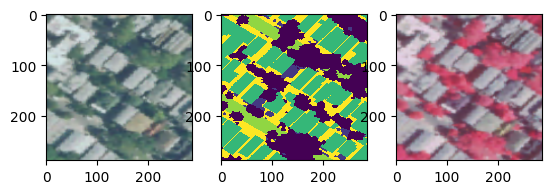

In [18]:
fp = '/home/chenying/data/weakFT/test/NYC_p288_test.lmdb'
env = lmdb.open(fp, readonly=True)
with env.begin() as txn:
    n = txn.stat()['entries']
    data_byte, data_shp, lbl_byte, lbl_shp, ind = pickle.loads(txn.get(str(0).encode()))
    img = np.frombuffer(data_byte, dtype=np.uint8).reshape(data_shp)
    lbl = np.frombuffer(lbl_byte, dtype=np.uint8).reshape(lbl_shp)
plt.figure()
plt.subplot(131)
plt.imshow(img[:3].transpose(1,2,0))
plt.subplot(132)
plt.imshow(lbl, interpolation='none')
plt.subplot(133)
plt.imshow(img[[3,0,1]].transpose(1,2,0))
print(n, ind, np.unique(lbl))

In [21]:
m = [0.485, 0.456, 0.406]
std=[0.229, 0.224, 0.225]
np.array(m)*255, np.array(std)*255

(array([123.675, 116.28 , 103.53 ]), array([58.395, 57.12 , 57.375]))